In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
words = open('../../src/zero_to_hero/part_02_makemore/names.txt', 'r').read().splitlines()

In [3]:
len(words)

32033

In [4]:
# We had S/E special tokens, but now just "."
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
vocab_size = len(itos)
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [5]:
# build the dataset
block_size = 3 # context length: how many characters do we take to predict the next one?

def build_dataset(words):  
  X, Y = [], []
  
  for w in words:
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      context = context[1:] + [ix] # crop and append

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr,  Ytr  = build_dataset(words[:n1])     # 80%
Xdev, Ydev = build_dataset(words[n1:n2])   # 10%
Xte,  Yte  = build_dataset(words[n2:])     # 10%

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [6]:
import numpy as np
# MLP revisited
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C  = torch.randn((vocab_size, n_embd),            generator=g)
W1 = torch.randn((n_embd * block_size, n_hidden), generator=g) * 5/3 / np.sqrt(n_embd * block_size) # tanh saturation step, Kaiming
b1 = torch.randn(n_hidden,                        generator=g) * 0.01 # tanh saturation step, helps to break symmetry
W2 = torch.randn((n_hidden, vocab_size),          generator=g) * 5/3 / np.sqrt(n_hidden) # Initialise step 1
b2 = torch.randn(vocab_size,                      generator=g) * 0.0 # initialise step 2

# BatchNorm parameters
bngain = torch.ones((1, n_hidden))
bnbias = torch.zeros((1, n_hidden))
bnmean_running = torch.zeros((1, n_hidden))
bnstd_running = torch.ones((1, n_hidden))

#parameters = [C, W1, W2, b2, bngain, bnbias]
parameters = [C, W1, b1, W2, b2]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.requires_grad = True

11897


In [7]:
# same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):
  
  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y
  
  # forward pass
  emb = C[Xb] # embed the characters into vectors
  embcat = emb.view(emb.shape[0], -1) # concatenate the vectors
  # Linear layer
  hpreact = embcat @ W1 + b1 # hidden layer pre-activation
  # Non-linearity
  h = torch.tanh(hpreact) # hidden layer
  logits = h @ W2 + b2 # output layer
  loss = F.cross_entropy(logits, Yb) # loss function
  
  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()
  
  # update
  lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  if i % 10000 == 0: # print every once in a while
    print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())


      0/ 200000: 4.1627
  10000/ 200000: 2.1838
  20000/ 200000: 2.3984
  30000/ 200000: 2.4408
  40000/ 200000: 1.9492
  50000/ 200000: 2.3230
  60000/ 200000: 2.4580
  70000/ 200000: 2.1214
  80000/ 200000: 2.3010
  90000/ 200000: 2.2164
 100000/ 200000: 1.8441
 110000/ 200000: 2.1224
 120000/ 200000: 1.8953
 130000/ 200000: 2.4402
 140000/ 200000: 2.0976
 150000/ 200000: 2.1316
 160000/ 200000: 1.8384
 170000/ 200000: 1.8277
 180000/ 200000: 1.8689
 190000/ 200000: 1.8078


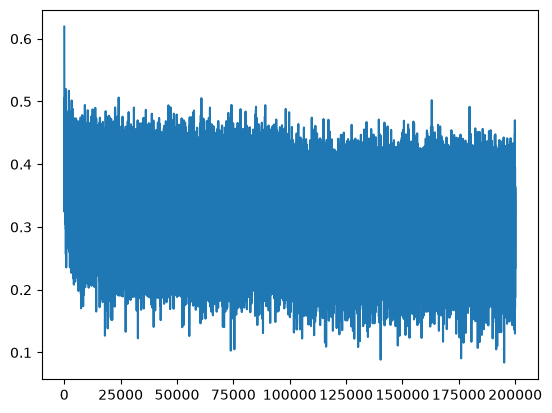

In [8]:
plt.plot(lossi)

In [9]:
# this decorator disables gradient tracking - if we won't ever call loss.backward, more efficient
@torch.no_grad() 
def split_loss(split):
  x,y = {
    'train': (Xtr, Ytr),
    'val': (Xdev, Ydev),
    'test': (Xte, Yte),
  }[split]
  emb = C[x] # (N, block_size, n_embd)
  embcat = emb.view(emb.shape[0], -1) # concat into (N, block_size * n_embd)
  hpreact = embcat @ W1  + b1
  h = torch.tanh(hpreact) # (N, n_hidden)
  logits = h @ W2 + b2 # (N, vocab_size)
  loss = F.cross_entropy(logits, y)
  print(split, loss.item())

split_loss('train')
split_loss('val')

train 2.037996768951416
val 2.1054441928863525


In [10]:
# Configuring initial loss - look at initialisation
# For us should be around log(27) (equal weighted model) (-log(1/27) is nll)
# Can use some initialisation technique (Glorot, He)

In [11]:
# we initialise b2 to 0, W2 by 0.01
# Don't do 0!

(array([ 989.,  212.,  156.,  108.,  102.,  106.,   72.,   74.,   73.,
          74.,   55.,   52.,   59.,   46.,   61.,   85.,   92.,   53.,
          83.,   76.,   68.,   77.,   80.,  122.,   85.,   98.,  134.,
         139.,  116.,   55.,   64.,   71.,   74.,   52.,   79.,   61.,
          54.,   82.,   55.,   68.,   59.,   71.,   87.,   80.,   93.,
         106.,  131.,  176.,  250., 1085.]),
 array([-9.99999881e-01, -9.59999883e-01, -9.19999886e-01, -8.79999888e-01,
        -8.39999890e-01, -7.99999893e-01, -7.59999895e-01, -7.19999897e-01,
        -6.79999900e-01, -6.39999902e-01, -5.99999905e-01, -5.59999907e-01,
        -5.19999909e-01, -4.79999912e-01, -4.39999914e-01, -3.99999917e-01,
        -3.59999919e-01, -3.19999921e-01, -2.79999924e-01, -2.39999926e-01,
        -1.99999928e-01, -1.59999931e-01, -1.19999933e-01, -7.99999356e-02,
        -3.99999380e-02,  5.96046448e-08,  4.00000572e-02,  8.00000548e-02,
         1.20000052e-01,  1.60000050e-01,  2.00000048e-01,  2.400000

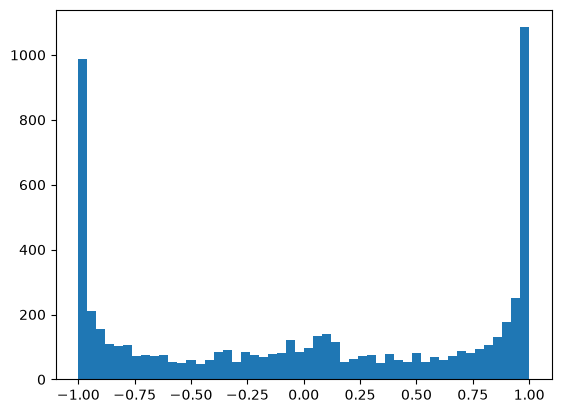

In [12]:
# Next... if we look at h (not hpreact), we get a lot of ones - saturated!
# This gives us really small gradients (gradient of tanh is (1 - t ** 2))
# h massively saturated, as hpreact very large
a1 = h.view(-1).tolist()
plt.hist(a1, 50)

(array([ 989.,  212.,  156.,  108.,  102.,  106.,   72.,   74.,   73.,
          74.,   55.,   52.,   59.,   46.,   61.,   85.,   92.,   53.,
          83.,   76.,   68.,   77.,   80.,  122.,   85.,   98.,  134.,
         139.,  116.,   55.,   64.,   71.,   74.,   52.,   79.,   61.,
          54.,   82.,   55.,   68.,   59.,   71.,   87.,   80.,   93.,
         106.,  131.,  176.,  250., 1085.]),
 array([-9.99999881e-01, -9.59999883e-01, -9.19999886e-01, -8.79999888e-01,
        -8.39999890e-01, -7.99999893e-01, -7.59999895e-01, -7.19999897e-01,
        -6.79999900e-01, -6.39999902e-01, -5.99999905e-01, -5.59999907e-01,
        -5.19999909e-01, -4.79999912e-01, -4.39999914e-01, -3.99999917e-01,
        -3.59999919e-01, -3.19999921e-01, -2.79999924e-01, -2.39999926e-01,
        -1.99999928e-01, -1.59999931e-01, -1.19999933e-01, -7.99999356e-02,
        -3.99999380e-02,  5.96046448e-08,  4.00000572e-02,  8.00000548e-02,
         1.20000052e-01,  1.60000050e-01,  2.00000048e-01,  2.400000

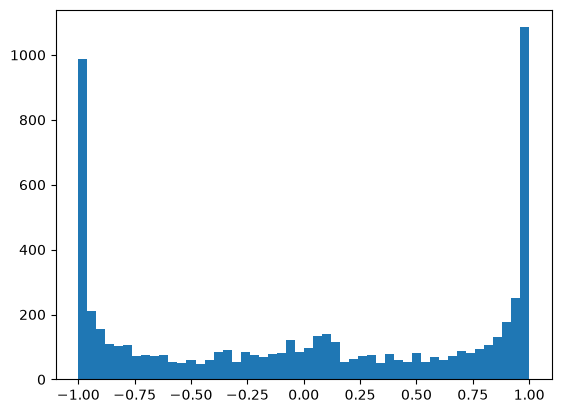

In [13]:
# post saturation fix
a1 = h.view(-1).tolist()
plt.hist(a1, 50)

(array([  3.,   4.,   2.,   4.,   5.,   8.,  15.,  17.,  24.,  31.,  39.,
         51.,  81.,  91., 122., 141., 167., 204., 220., 251., 323., 356.,
        568., 896., 501., 366., 302., 297., 238., 197., 191., 154., 132.,
         96.,  68.,  48.,  55.,  40.,  23.,  23.,  19.,  11.,   6.,   4.,
          2.,   1.,   1.,   1.,   0.,   1.]),
 array([-8.25280762, -7.90016085, -7.54751408, -7.19486731, -6.84222054,
        -6.48957376, -6.13692699, -5.78428022, -5.43163345, -5.07898668,
        -4.72633991, -4.37369314, -4.02104637, -3.6683996 , -3.31575283,
        -2.96310606, -2.61045929, -2.25781252, -1.90516575, -1.55251898,
        -1.19987221, -0.84722544, -0.49457867, -0.1419319 ,  0.21071487,
         0.56336164,  0.91600842,  1.26865519,  1.62130196,  1.97394873,
         2.3265955 ,  2.67924227,  3.03188904,  3.38453581,  3.73718258,
         4.08982935,  4.44247612,  4.79512289,  5.14776966,  5.50041643,
         5.8530632 ,  6.20570997,  6.55835674,  6.91100351,  7.26365028,
 

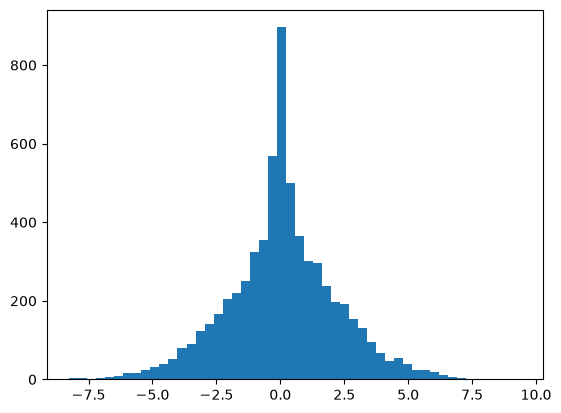

In [14]:
plt.hist(hpreact.view(-1).tolist(), 50)

In [15]:
# However we see that no neuron has all examples giving saturated tanh (___dead neuron___)
# So some gradients will flow through
# How do dead neurons happen? What about with high learning rate?

In [16]:
# We scale W1, b1 by 0.2, 0.01
# Loss (2.06/2.13) -> (2.03/2.10)

In [17]:
# In deeper problems, these are _must fix_ and can blow up if not fixed
# Here, we just needed to train more

## Magic numbers

In [18]:
# Next, we deal with initialisation magic numbers

In [19]:
# We want to preserve variance across layers, leading us to normal Glorot or Kaiming initialisation
# Divide by square root of fan in (He) Note with Tanh we would lose the factor of 2 that He keeps for ReLU (this is gain for nonlinearity in pytorch)
# Delving deep into rectifiers - paper that has this
# Karpathy suggests Kaiming is common
# Gain is for "contracting" functions in some way - scale up to get past contracting and preserve variance

In [20]:
# Things like residual connections, batch normalisation etc, and Adam make it less crucial to initialise
# Kaiming and done is fine

In [21]:
# Loss (2.03/2.10) -> (2.03/2.10)

## Batch Normalization

In [22]:
# Core idea, just force hpreact and normalise to be standard gaussian
# This is differentiable, so okay

In [23]:
# We don't want it to be always unit gaussian, want it shifted around
# So we take unit_gaussian -> c1*unit_gaussian + c2 for some constants
# These are learned - start again at 47:00 (c1 =1, c2 =0 at the start)

In [24]:
# Shouldn't really expect an improvement - our initialisation did it
# This helps for more complicated neural nets
# Note that logit for an example is now a function of what is in the batch
# mean/std slightly unstable - acts as a regulariser

In [25]:
# Question - how do we predict from a single example?
# The NN expects batches, so what is bnean?
# At the end of training, measure mean/std over the entire training set to get bnmean and bnstd, use these

In [26]:
# same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):
  
  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y
  
  # forward pass
  emb = C[Xb] # embed the characters into vectors
  embcat = emb.view(emb.shape[0], -1) # concatenate the vectors
  # Linear layer
  hpreact = embcat @ W1 + b1 # hidden layer pre-activation
  hpreact = bngain * (hpreact - hpreact.mean(axis=0, keepdim=True)) / hpreact.std(0, keepdim=True) + bnbias
  # Non-linearity
  h = torch.tanh(hpreact) # hidden layer
  logits = h @ W2 + b2 # output layer
  loss = F.cross_entropy(logits, Yb) # loss function
  
  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()
  
  # update
  lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  if i % 10000 == 0: # print every once in a while
    print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())


      0/ 200000: 2.6163
  10000/ 200000: 1.8143
  20000/ 200000: 2.5440
  30000/ 200000: 2.5385
  40000/ 200000: 2.4167
  50000/ 200000: 2.4710
  60000/ 200000: 2.2385
  70000/ 200000: 1.7796
  80000/ 200000: 2.3218
  90000/ 200000: 2.2942
 100000/ 200000: 1.7806
 110000/ 200000: 1.9577
 120000/ 200000: 2.1006
 130000/ 200000: 2.3166
 140000/ 200000: 2.0675
 150000/ 200000: 2.5263
 160000/ 200000: 2.2421
 170000/ 200000: 2.1954
 180000/ 200000: 1.9365
 190000/ 200000: 2.2797


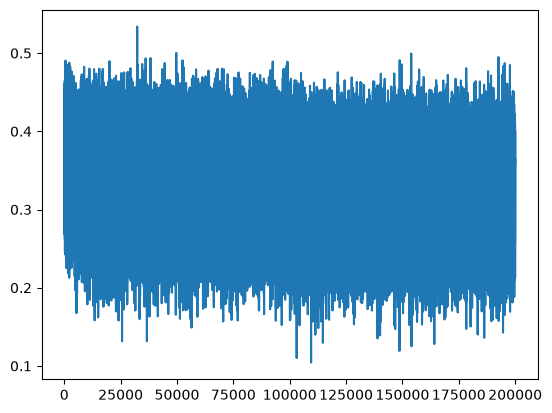

In [28]:
plt.plot(lossi)